# Titanic: Data Cleaning & Survival Analysis
**Abdelmonem | Data Analyst & Aspiring Data Scientist**

نسخة جديدة مبنية على `Titanic_cleaning.ipynb`. الملف الأصلي محفوظ بدون تعديل.
الهدف: تنظيف بيانات الركاب، دراسة الارتباطات بالنجاة، وتقديم نتائج قابلة لإعادة التشغيل.
هذا تحليل وصفي لعينة التدريب، وليس نموذج تنبؤ ولا إثبات علاقة سببية.

## خريطة التعديلات
| العلامة | التعديل | السبب |
|---|---|---|
| MODIFIED 01 | تحميل نسبي للبيانات | التشغيل محليًا أو على Colab بعد رفع train.csv |
| MODIFIED 02 | فحص جودة ومدخلات | اكتشاف أخطاء الملف قبل التحليل |
| MODIFIED 03 | تعويض العمر مع AgeWasMissing | الحفاظ على معرفة القيم المقدرة |
| MODIFIED 04 | الاحتفاظ بـ Cabin وإضافة HasCabin | توثيق المفقود دون اختراع أرقام كبائن |
| MODIFIED 05 | رصد Fare بالـIQR مع الاحتفاظ بالقيم | الأسعار المرتفعة ليست بالضرورة أخطاء |
| MODIFIED 06 | تصحيح IsChild وتوضيح العمر | الطفل أقل من 16 سنة، مع فصل المعروف عن المقدر |
| MODIFIED 07 | حفظ كل الرسومات وإضافة معدلات النجاة | المقارنة بين مجموعات مختلفة الحجم |
| MODIFIED 08 | شرح تحت كل رسم ونتائج وحدود | تحويل الرسومات إلى تحليل قابل للفهم |
| MODIFIED 09 | تصدير بيانات وملخص وفحوص نهائية | التحقق من اكتمال التنفيذ |

## التشغيل
ثبت المتطلبات من `requirements.txt`، وافتح هذه النوتبوك بجوار `train.csv` ثم Run All.
في Colab ارفع النوتبوك وملف `train.csv` إلى مجلد العمل نفسه. لا تحتاج إلى ربط Google Drive.

In [1]:
# MODIFIED 01: portable paths and consistent chart style
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / 'train.csv'
if not DATA_PATH.is_file():
    raise FileNotFoundError('Place train.csv in the working directory beside this notebook.')
FIGURES_DIR = BASE_DIR / 'figures'
OUTPUT_DIR = BASE_DIR / 'output'
FIGURES_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
COLORS = {0: '#c56b54', 1: '#247d8d'}
plt.rcParams.update({'figure.figsize': (10, 5.5), 'figure.dpi': 110})

def save_figure(fig, filename):
    fig.savefig(FIGURES_DIR / filename, dpi=220, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

def survival_summary(column, frame=None):
    data = df_clean if frame is None else frame
    out = data.groupby(column, observed=True)['Survived'].agg(Passengers='size', Survivors='sum', SurvivalRate='mean')
    out['SurvivalPercent'] = (100 * out['SurvivalRate']).round(2)
    return out

df = pd.read_csv(DATA_PATH)
display(df.head())
print('Rows and columns:', df.shape)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Rows and columns: (891, 12)


## 1. فحص البيانات قبل التنظيف
كل صف يمثل راكبًا في ملف التدريب. `Survived`: صفر لم ينجُ وواحد نجا.
`Pclass`: درجة التذكرة؛ `SibSp`: عدد الأشقاء/الزوج أو الزوجة؛ `Parch`: الآباء/الأبناء على السفينة.
`Fare` سعر مسجل للتذكرة وقد يعكس حجزًا مشتركًا؛ لا نعامله كدخل الراكب.
`Embarked`: C = Cherbourg، Q = Queenstown، S = Southampton.

In [2]:
# MODIFIED 02: explicit data-quality checks
df.columns = df.columns.str.strip()
required = {'PassengerId','Survived','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked','Cabin'}
assert required.issubset(df.columns), 'Required columns are missing.'
assert df['PassengerId'].is_unique, 'Duplicate PassengerId values require review.'
assert df['Survived'].isin([0, 1]).all()
assert df['Pclass'].isin([1, 2, 3]).all()
assert df['Age'].dropna().between(0, 120).all()
assert df['Fare'].dropna().ge(0).all()
df.info()
display(df.describe().T)
missing_before = df.isna().sum()
display(pd.DataFrame({'Missing': missing_before, 'Percent': (missing_before / len(df) * 100).round(2)}))
print('Exact duplicate rows:', int(df.duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


,Missing,Percent
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


Exact duplicate rows: 0


## 2. تنظيف وتعويض القيم الناقصة
نحتفظ بنسخة خام، ونزيل المسافات من النصوص. نعوض `Embarked` بالمنوال المحسوب من الملف.
نعوض العمر بوسيط مجموعة `Pclass` و`Sex` مثل المشروع الأصلي، مع وسيط عام كحل احتياطي.
`AgeWasMissing` يحفظ مصدر العمر؛ التعويض قد يصنع قممًا إضافية في توزيع الأعمار.

### MODIFIED 04: قرار Cabin
نحتفظ بعمود `Cabin` كما هو بقيمه الناقصة، ونضيف `HasCabin` كعلامة لتوافر المعلومة.
غياب رقم الكابينة لا يعني أن الراكب بلا كابينة. لا نحذف 687 صفًا ولا نخترع أرقامًا لها.
وجود المعلومة قد يرتبط بدرجة التذكرة أو أسلوب التسجيل، ولذلك لا نفسره كسبب للنجاة.

In [3]:
# MODIFIED 03 and 04: documented missing-value treatment
df_clean = df.copy(deep=True)
for column in df_clean.select_dtypes(include=['object', 'string']).columns:
    df_clean[column] = df_clean[column].str.strip().replace('', np.nan)
df_clean['AgeWasMissing'] = df_clean['Age'].isna().astype('int8')
df_clean['EmbarkedWasMissing'] = df_clean['Embarked'].isna().astype('int8')
embarked_mode = df_clean['Embarked'].mode().iloc[0]
df_clean['Embarked'] = df_clean['Embarked'].fillna(embarked_mode)
age_medians = df_clean.groupby(['Pclass', 'Sex'])['Age'].transform('median')
df_clean['Age'] = df_clean['Age'].fillna(age_medians).fillna(df_clean['Age'].median())
df_clean['HasCabin'] = df_clean['Cabin'].notna().astype('int8')
display(pd.DataFrame({'Before': missing_before, 'After': df_clean[df.columns].isna().sum()}))
display(df.groupby(['Pclass','Sex'])['Age'].median().rename('Median used for age imputation'))

,Before,After
PassengerId,0,0
Survived,0,0
Pclass,0,0
Name,0,0
Sex,0,0
Age,177,0
SibSp,0,0
Parch,0,0
Ticket,0,0
Fare,0,0


Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Median used for age imputation, dtype: float64

## 3. القيم المرتفعة والخصائص الجديدة
نحسب IQR = Q3 - Q1؛ وأي Fare أكبر من Q3 + 1.5 × IQR نعلّمه بـ`FareHighOutlier`.
هذا كشف إحصائي وليس قرار حذف؛ نحتفظ بكل الصفوف لأن اختلاف فئات التذاكر قد يفسر الأسعار.
`FamilySize = SibSp + Parch + 1` و`IsAlone = 1` لمن حجم أسرته المسجل يساوي واحدًا.
`IsChild` يعني عمرًا أقل من 16 سنة، وقد يعتمد على عمر مقدر؛ لذلك نحسب عدد الأطفال بعمر معلوم أيضًا.
اسم `Is Child` في النسخة الأصلية أصبح `IsChild`، والتعليق القديم >16 تم تصحيحه إلى <16.

In [4]:
# MODIFIED 05 and 06: retain outliers; track imputed ages
q1, q3 = df_clean['Fare'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
df_clean['FareHighOutlier'] = (df_clean['Fare'] > upper_bound).astype('int8')
df_clean['FamilySize'] = df_clean['SibSp'] + df_clean['Parch'] + 1
df_clean['IsAlone'] = (df_clean['FamilySize'] == 1).astype('int8')
df_clean['IsChild'] = (df_clean['Age'] < 16).astype('int8')
print(f'Fare Q1={q1:.4f}, Q3={q3:.4f}, IQR={iqr:.4f}, upper fence={upper_bound:.4f}')
print('High-fare observations retained:', int(df_clean['FareHighOutlier'].sum()))
print('Children using filled Age:', int(df_clean['IsChild'].sum()))
print('Children with observed Age:', int(df['Age'].lt(16).sum()))
print('Children assigned from imputed Age:', int(((df_clean['IsChild']==1)&(df_clean['AgeWasMissing']==1)).sum()))
display(survival_summary('IsAlone'))

Fare Q1=7.9104, Q3=31.0000, IQR=23.0896, upper fence=65.6344
High-fare observations retained: 116
Children using filled Age: 83
Children with observed Age: 83
Children assigned from imputed Age: 0


,Passengers,Survivors,SurvivalRate,SurvivalPercent
IsAlone,,,,
0,354,179,0.505650,50.56
1,537,163,0.303538,30.35


## 4.1 Survival counts

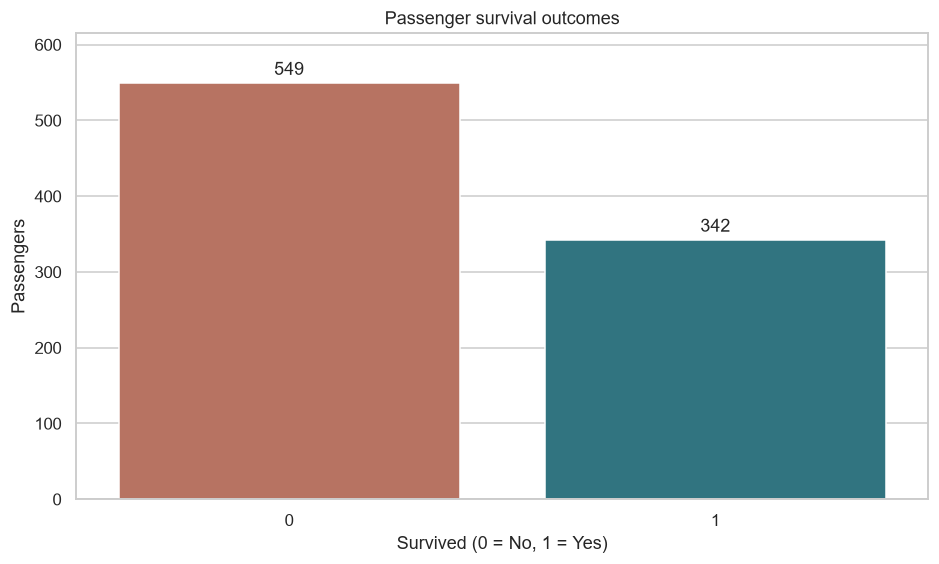

Overall survival: 38.38%


In [5]:
# MODIFIED 07: labeled chart and automatic image export
fig, ax = plt.subplots()
sns.countplot(data=df_clean, x='Survived', hue='Survived', palette=COLORS, legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, padding=3)
ax.set(title='Passenger survival outcomes', xlabel='Survived (0 = No, 1 = Yes)', ylabel='Passengers')
ax.margins(y=0.12)
save_figure(fig, '01_survival_counts.png')
print(f"Overall survival: {df_clean['Survived'].mean():.2%}")

### شرح الرسمة وقراءتها
المحور الأفقي يقسم الركاب إلى لم ينجُ ونجا، والرأسي يمثل عدد الركاب. الأرقام فوق الأعمدة تعطي العدد الفعلي. هذه نقطة البداية لفهم عدم توازن النتيجة؛ لا نفترض أن فرص النجاة كانت متساوية لمجرد وجود فئتين. نسب النجاة هنا تخص ملف التدريب فقط.

## 4.2 Sex and survival counts

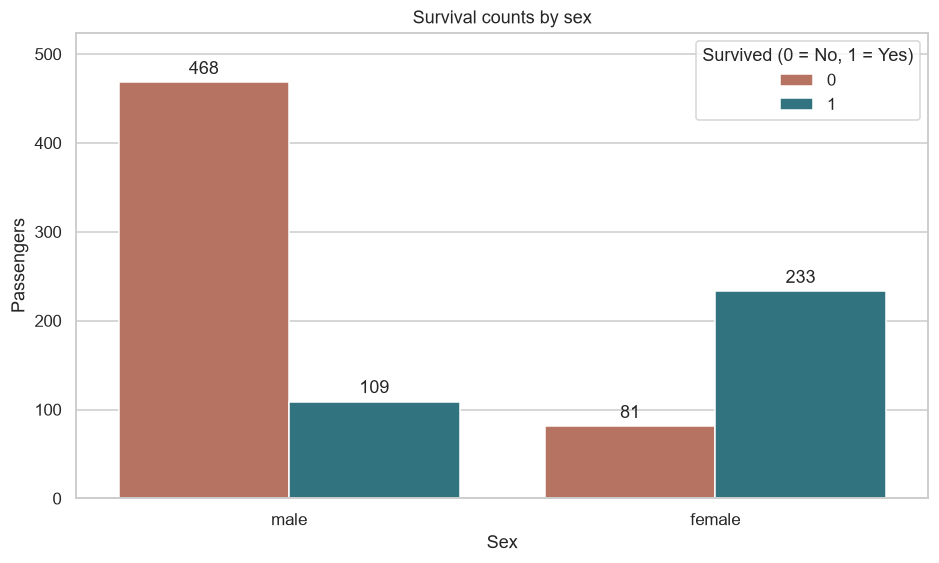

,Passengers,Survivors,SurvivalRate,SurvivalPercent
Sex,,,,
female,314,233,0.742038,74.20
male,577,109,0.188908,18.89


In [6]:
fig, ax = plt.subplots()
sns.countplot(data=df_clean, x='Sex', hue='Survived', hue_order=[0,1], palette=COLORS, ax=ax)
for container in ax.containers:
    ax.bar_label(container, padding=3)
ax.set(title='Survival counts by sex', xlabel='Sex', ylabel='Passengers')
ax.legend(title='Survived (0 = No, 1 = Yes)')
ax.margins(y=0.12)
save_figure(fig, '02_sex_survival_counts.png')
display(survival_summary('Sex'))

### شرح الرسمة وقراءتها
داخل كل فئة للجنس نقارن عمود الناجين بعمود غير الناجين. ارتفاع عدد الركاب الذكور يؤثر في الأعداد المطلقة، لذلك يجب قراءة جدول نسبة النجاة مع الرسم. الفروق المرصودة ارتباطات في العينة وقد تتداخل مع الدرجة والعمر؛ لا يمثل الجنس وحده تفسيرًا سببيًا.

## 4.3 Passenger class and survival counts

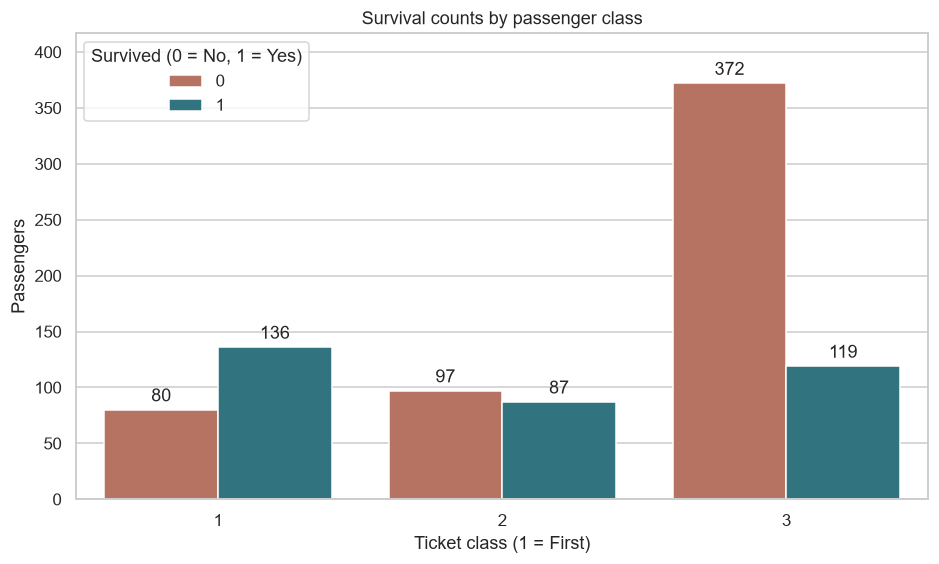

,Passengers,Survivors,SurvivalRate,SurvivalPercent
Pclass,,,,
1,216,136,0.629630,62.96
2,184,87,0.472826,47.28
3,491,119,0.242363,24.24


In [7]:
fig, ax = plt.subplots()
sns.countplot(data=df_clean, x='Pclass', hue='Survived', hue_order=[0,1], palette=COLORS, ax=ax)
for container in ax.containers:
    ax.bar_label(container, padding=3)
ax.set(title='Survival counts by passenger class', xlabel='Ticket class (1 = First)', ylabel='Passengers')
ax.legend(title='Survived (0 = No, 1 = Yes)')
ax.margins(y=0.12)
save_figure(fig, '03_class_survival_counts.png')
display(survival_summary('Pclass'))

### شرح الرسمة وقراءتها
المحور الأفقي يوضح درجات التذاكر من الأولى إلى الثالثة. نقارن الناجين وغير الناجين داخل كل درجة، ثم نستخدم معدلات النجاة للمقارنة بين الدرجات المختلفة في الحجم. ارتفاع عدد الوفيات في الثالثة يحتاج إلى النظر إلى عدد ركابها أيضًا. الرسم لا يعزل أثر الجنس أو العمر أو موقع الراكب.

## 4.4 Age distribution by survival

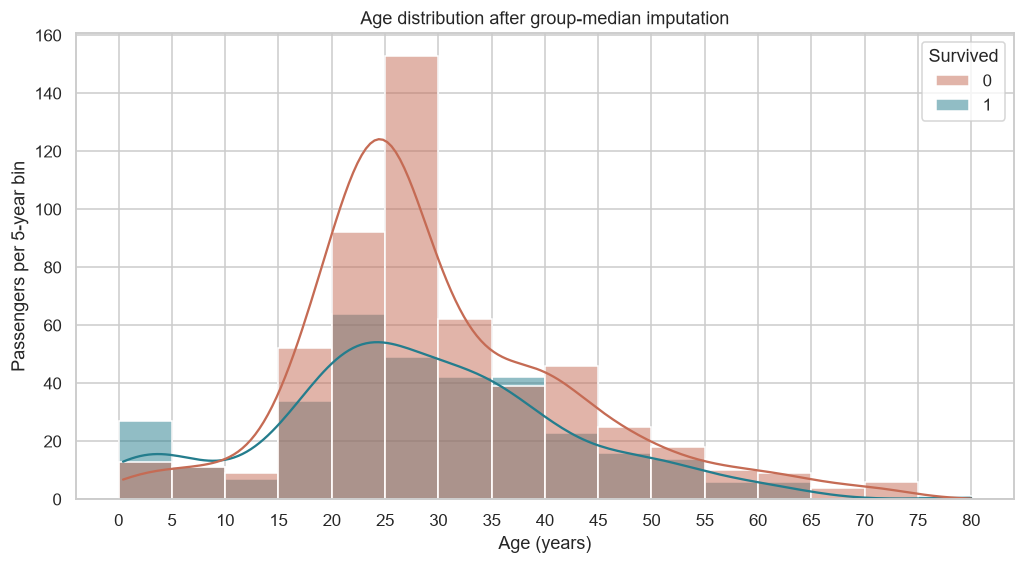

In [8]:
fig, ax = plt.subplots(figsize=(11,5.5))
sns.histplot(data=df_clean, x='Age', hue='Survived', hue_order=[0,1], palette=COLORS,
             binwidth=5, binrange=(0,80), multiple='layer', alpha=0.5, kde=True, ax=ax)
ax.set(title='Age distribution after group-median imputation', xlabel='Age (years)', ylabel='Passengers per 5-year bin')
ax.set_xticks(range(0,85,5))
save_figure(fig, '04_age_distribution.png')

### شرح الرسمة وقراءتها
كل عمود يمثل نطاقًا عمريًا عرضه خمس سنوات، واللون يميز النتيجة. خطوط KDE تلخص شكل التوزيع ولا تمثل احتمالات نجاة مباشرة. القمم قرب بعض الأعمار تتأثر بتعويض الأعمار المفقودة بوسيط المجموعة؛ العدد الأكبر في عمر معين لا يثبت ارتفاع أو انخفاض فرص النجاة فيه.

## 4.5 Age distribution using observed ages only

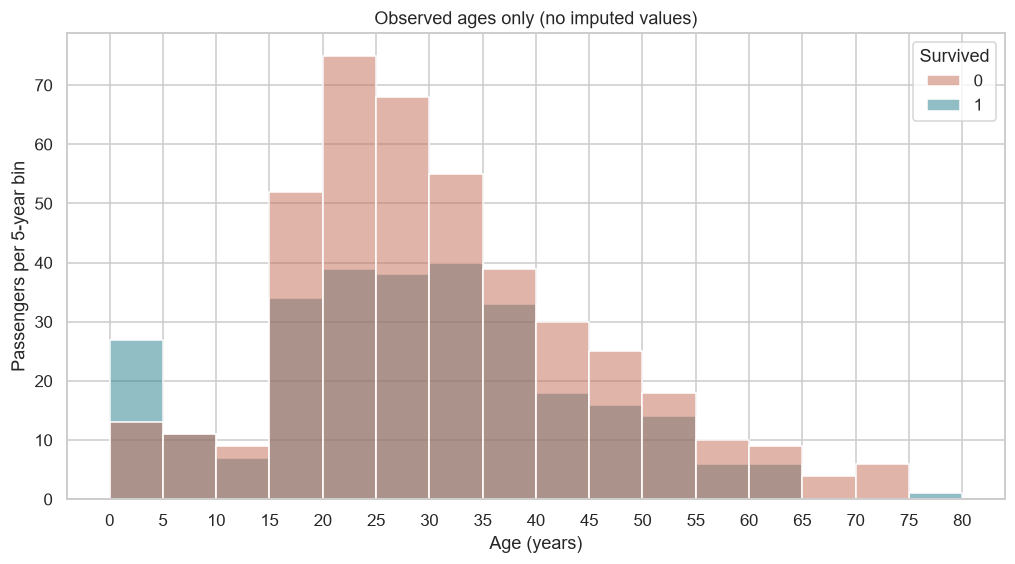

Observed ages: 714 | Excluded missing ages: 177


In [9]:
# MODIFIED: replace duplicate age plot with an imputation sensitivity check
observed_age = df_clean.loc[df_clean['AgeWasMissing'].eq(0)]
fig, ax = plt.subplots(figsize=(11,5.5))
sns.histplot(data=observed_age, x='Age', hue='Survived', hue_order=[0,1], palette=COLORS,
             binwidth=5, binrange=(0,80), multiple='layer', alpha=0.5, ax=ax)
ax.set(title='Observed ages only (no imputed values)', xlabel='Age (years)', ylabel='Passengers per 5-year bin')
ax.set_xticks(range(0,85,5))
save_figure(fig, '05_age_observed_only.png')
print('Observed ages:', len(observed_age), '| Excluded missing ages:', int(df_clean['AgeWasMissing'].sum()))

### شرح الرسمة وقراءتها
نفس تقسيم الأعمار السابق، لكن الرسم يستبعد الركاب الذين كانت أعمارهم مفقودة. المقارنة مع الرسم السابق توضح مدى تأثر الشكل بالتعويض. هذا فحص حساسية مفيد، لكنه لا يلغي تحيز غياب العمر؛ الركاب ذوو العمر المعروف قد يختلفون عن بقية الركاب.

## 4.6 Fare distribution by class

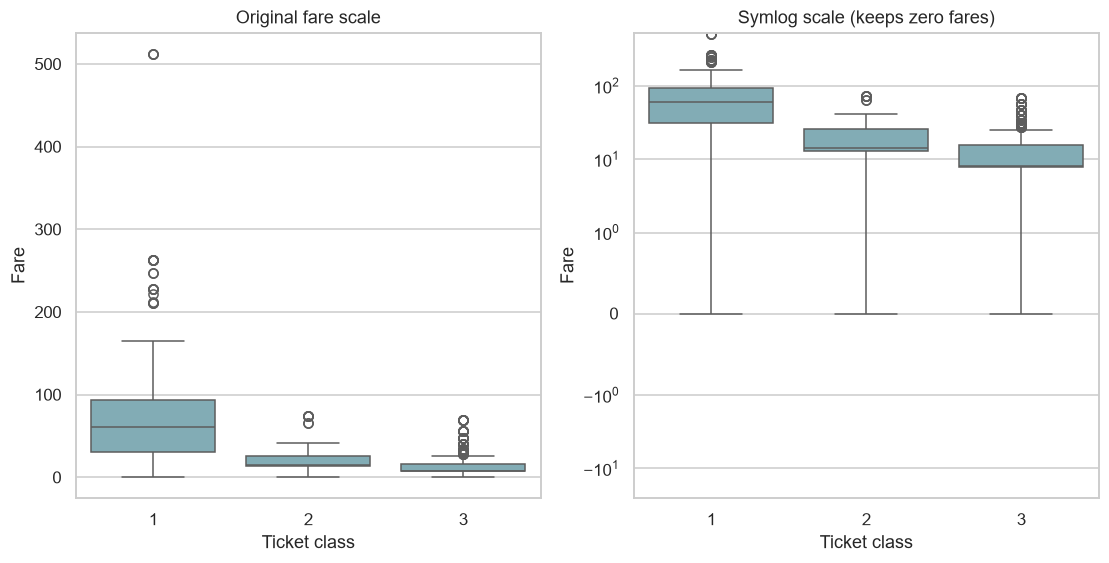

,count,median,min,max
Pclass,,,,
1,216,60.2875,0.0,512.3292
2,184,14.2500,0.0,73.5000
3,491,8.0500,0.0,69.5500


In [10]:
fig, axes = plt.subplots(1,2,figsize=(12,5.5))
for ax in axes:
    sns.boxplot(data=df_clean, x='Pclass', y='Fare', color='#79b2bd', ax=ax)
    ax.set(xlabel='Ticket class', ylabel='Fare')
axes[0].set_title('Original fare scale')
axes[1].set_yscale('symlog', linthresh=1)
axes[1].set_title('Symlog scale (keeps zero fares)')
save_figure(fig, '06_fare_boxplot.png')
display(df_clean.groupby('Pclass')['Fare'].agg(['count','median','min','max']))

### شرح الرسمة وقراءتها
الخط داخل الصندوق يمثل الوسيط، وحدا الصندوق الربيعين الأول والثالث. الشوارب تمتد لأبعد قيمة داخل 1.5 IQR، والنقاط خارجها قيم إحصائية متطرفة وليست أخطاء مؤكدة. اللوحة اليسرى تعرض الأسعار الأصلية؛ اليمنى تغير المقياس لتسهيل رؤية القيم الصغيرة مع إبقاء الصفر. لا نخلط المسافات بين اللوحتين ولا نحذف الأسعار العالية تلقائيًا.

## 4.7 Focused pairplot

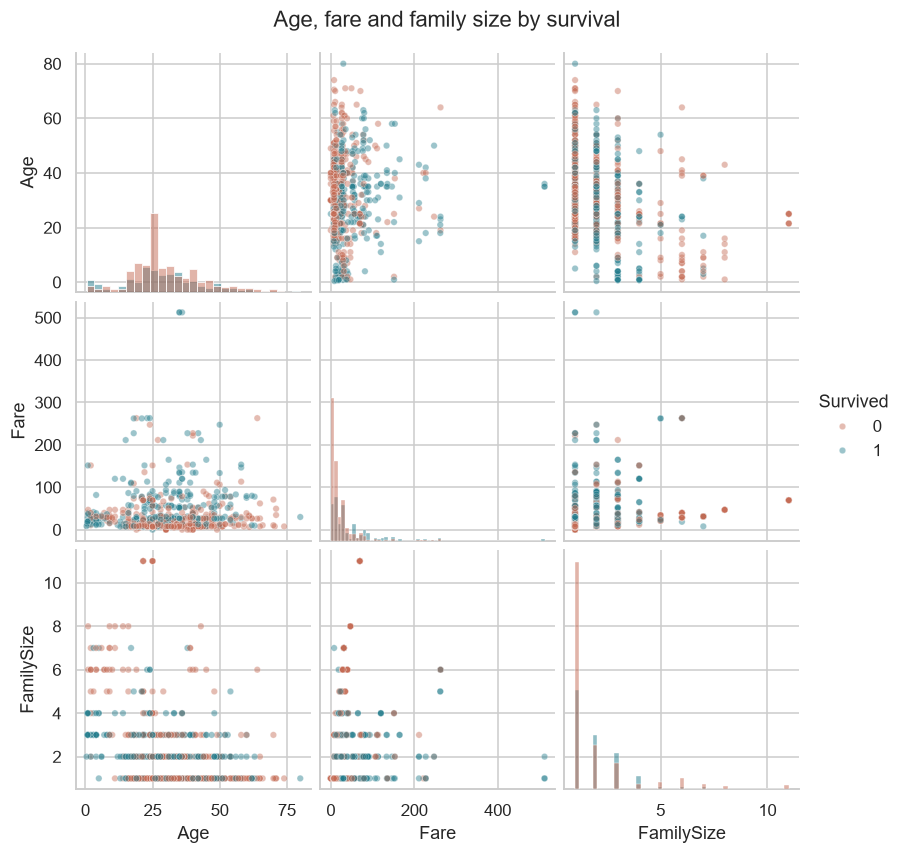

In [11]:
# MODIFIED: meaningful continuous/count features instead of identifiers and every binary flag
g = sns.pairplot(df_clean, vars=['Age','Fare','FamilySize'], hue='Survived',
                 hue_order=[0,1], palette=COLORS, diag_kind='hist',
                 plot_kws={'alpha':0.45, 's':18}, height=2.5)
g.figure.suptitle('Age, fare and family size by survival', y=1.03)
save_figure(g.figure, '07_pairplot.png')

### شرح الرسمة وقراءتها
كل لوحة خارج القطر تعرض متغيرين، والقطر يعرض توزيع متغير واحد. اللون يوضح النجاة، وتداخل النقاط يعني أن المتغيرات لا تفصل النتيجة فصلًا تامًا. استبعدنا PassengerId لأنه معرّف، وقللنا المتغيرات الثنائية لتوضيح الرسم. Fare شديد الالتواء وFamilySize متقطع، والعمر يحتوي قيمًا مقدرة؛ لذلك لا نستنتج علاقة خطية أو سببية من الشكل وحده.

## 4.8 Comparable survival rates

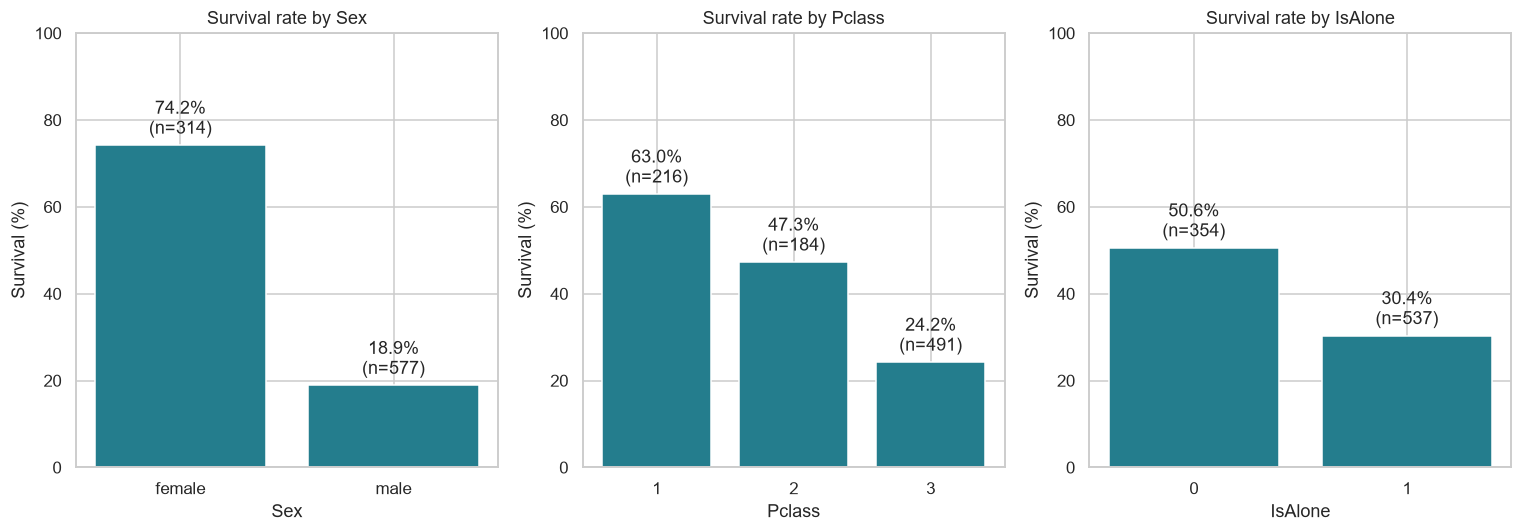

In [12]:
fig, axes = plt.subplots(1,3,figsize=(14,5))
for ax, column in zip(axes, ['Sex','Pclass','IsAlone']):
    table = survival_summary(column)
    bars = ax.bar(table.index.astype(str), table['SurvivalPercent'], color='#247d8d')
    ax.bar_label(bars, labels=[f'{rate:.1f}%\n(n={n})' for rate,n in zip(table['SurvivalPercent'],table['Passengers'])], padding=4)
    ax.set(title=f'Survival rate by {column}', xlabel=column, ylim=(0,100), ylabel='Survival (%)')
fig.tight_layout()
save_figure(fig, '08_survival_rates.png')

### شرح الرسمة وقراءتها
المحور الرأسي هنا نسبة الناجين داخل المجموعة، وليس العدد الكلي. n فوق كل عمود هو حجم المجموعة، وهذا يجعل المقارنة أوضح من مقارنة الأعداد وحدها. IsAlone = 1 يعني السفر دون أقارب مسجلين في SibSp وParch. اختلاف المعدلات لا يثبت أن السفر مع الأسرة سبب النجاة، ولا توجد فترات ثقة أو اختبارات دلالة في هذا الرسم.

## 4.9 Cabin information and survival

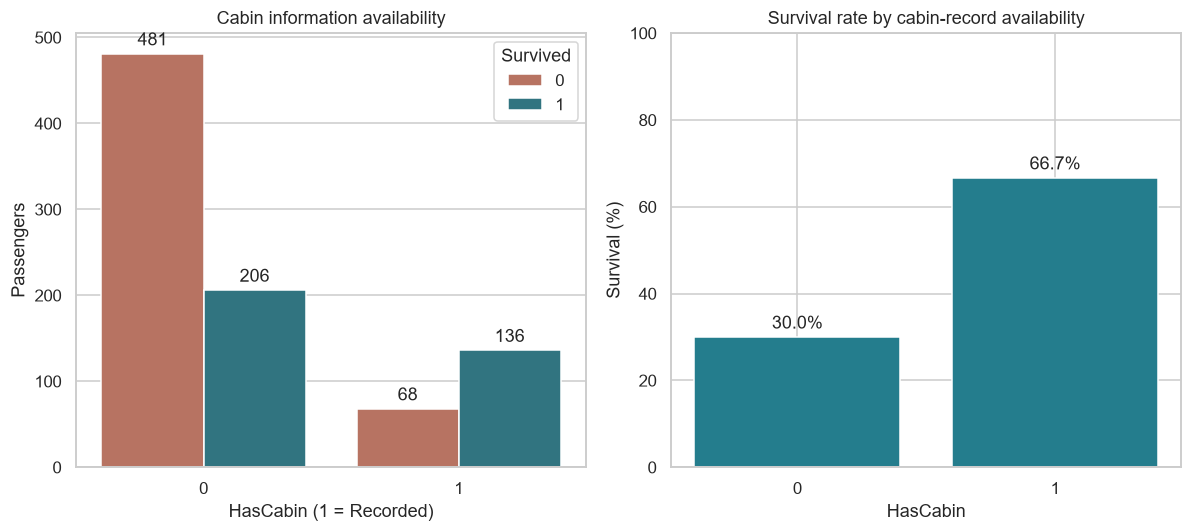

,Passengers,Survivors,SurvivalRate,SurvivalPercent
HasCabin,,,,
0,687,206,0.299854,29.99
1,204,136,0.666667,66.67


HasCabin,0,1
Pclass,,
1,0.185,0.815
2,0.913,0.087
3,0.976,0.024


In [13]:
fig, axes = plt.subplots(1,2,figsize=(11,5))
sns.countplot(data=df_clean, x='HasCabin', hue='Survived', hue_order=[0,1], palette=COLORS, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)
axes[0].set(title='Cabin information availability', xlabel='HasCabin (1 = Recorded)', ylabel='Passengers')
table = survival_summary('HasCabin')
bars = axes[1].bar(table.index.astype(str), table['SurvivalPercent'], color='#247d8d')
axes[1].bar_label(bars, fmt='%.1f%%', padding=3)
axes[1].set(title='Survival rate by cabin-record availability', xlabel='HasCabin', ylabel='Survival (%)', ylim=(0,100))
fig.tight_layout()
save_figure(fig, '09_cabin_information.png')
display(table)
display(pd.crosstab(df_clean['Pclass'],df_clean['HasCabin'],normalize='index').round(3))

### شرح الرسمة وقراءتها
اللوحة الأولى تعرض أعداد الناجين وغير الناجين حسب توافر رقم الكابينة، والثانية النسبة داخل كل مجموعة. HasCabin يقيس اكتمال التسجيل وليس امتلاك كابينة. جدول التوزيع حسب الدرجة يساعد على كشف تداخل توافر المعلومة مع الدرجة؛ لذلك لا ننسب الفرق لوجود رقم الكابينة كعامل سببي مستقل.

## 5. النتائج المحسوبة وحدود المشروع
MODIFIED 08: نولد الخلاصة من الجداول بدل كتابة أرقام قد تصبح قديمة عند تغيير البيانات.
لا يوجد تدريب نموذج أو قياس دقة في هذا المشروع. بيانات التدريب لا تمثل كامل ركاب السفينة.
عند بناء نموذج لاحقًا يجب تقسيم التدريب والتحقق أولًا، وتعلم وسطاء التعويض والمنوال من جزء التدريب فقط لتجنب تسرب البيانات.

In [14]:
sex_rates = survival_summary('Sex')
class_rates = survival_summary('Pclass')
alone_rates = survival_summary('IsAlone')
summary = {
    'rows': len(df_clean), 'columns_original': len(df.columns),
    'survivors': int(df_clean['Survived'].sum()),
    'non_survivors': int(df_clean['Survived'].eq(0).sum()),
    'survival_percent': round(df_clean['Survived'].mean()*100,2),
    'age_imputed': int(df_clean['AgeWasMissing'].sum()),
    'embarked_imputed': int(df_clean['EmbarkedWasMissing'].sum()),
    'cabin_missing_retained': int(df_clean['Cabin'].isna().sum()),
    'fare_upper_fence': float(upper_bound),
    'fare_outliers_retained': int(df_clean['FareHighOutlier'].sum()),
    'children_after_imputation': int(df_clean['IsChild'].sum()),
    'children_observed_age': int(df['Age'].lt(16).sum()),
    'sex_survival_percent': sex_rates['SurvivalPercent'].to_dict(),
    'class_survival_percent': {str(k):v for k,v in class_rates['SurvivalPercent'].to_dict().items()},
    'alone_survival_percent': {str(k):v for k,v in alone_rates['SurvivalPercent'].to_dict().items()}
}
display(Markdown(f"""### النتائج
- عدد الركاب: **{summary['rows']}**؛ الناجون: **{summary['survivors']}** ({summary['survival_percent']}%).
- نجاة الإناث: **{sex_rates.loc['female','SurvivalPercent']}%**؛ الذكور: **{sex_rates.loc['male','SurvivalPercent']}%**.
- نسبة النجاة حسب الدرجة: الأولى **{class_rates.loc[1,'SurvivalPercent']}%**، الثانية **{class_rates.loc[2,'SurvivalPercent']}%**، الثالثة **{class_rates.loc[3,'SurvivalPercent']}%**.
- المسافرون وحدهم: **{alone_rates.loc[1,'SurvivalPercent']}%** مقابل **{alone_rates.loc[0,'SurvivalPercent']}%** لمن معهم أقارب مسجلون.
- عوضنا **{summary['age_imputed']}** عمرًا و**{summary['embarked_imputed']}** قيمة لميناء الصعود، واحتفظنا بـ**{summary['cabin_missing_retained']}** قيمة Cabin مفقودة بتوثيق واضح.
- عدد الأطفال بعد التعويض: **{summary['children_after_imputation']}**؛ بعمر مسجل فعليًا: **{summary['children_observed_age']}**.

هذه ارتباطات وصفية، وقد تتداخل الدرجة والجنس والعمر وحجم الأسرة وجودة تسجيل البيانات.
"""))

### النتائج
- عدد الركاب: **891**؛ الناجون: **342** (38.38%).
- نجاة الإناث: **74.2%**؛ الذكور: **18.89%**.
- نسبة النجاة حسب الدرجة: الأولى **62.96%**، الثانية **47.28%**، الثالثة **24.24%**.
- المسافرون وحدهم: **30.35%** مقابل **50.56%** لمن معهم أقارب مسجلون.
- عوضنا **177** عمرًا و**2** قيمة لميناء الصعود، واحتفظنا بـ**687** قيمة Cabin مفقودة بتوثيق واضح.
- عدد الأطفال بعد التعويض: **83**؛ بعمر مسجل فعليًا: **83**.

هذه ارتباطات وصفية، وقد تتداخل الدرجة والجنس والعمر وحجم الأسرة وجودة تسجيل البيانات.


## 6. تصدير النتائج والتحقق النهائي
MODIFIED 09: حفظ البيانات المنظفة وملخص رقمي؛ الفحوص تسمح فقط بمفقود Cabin الموثق.
الملف الخام لا يتغير، وكل رسمة تحفظ في `figures/` قبل عرضها.

In [15]:
assert len(df_clean) == len(df), 'No passenger rows should be silently removed.'
assert df_clean['PassengerId'].is_unique
assert df_clean.drop(columns=['Cabin']).notna().all().all()
assert df_clean['Cabin'].isna().sum() == df['Cabin'].isna().sum()
assert df_clean['Survived'].equals(df['Survived'])
assert df_clean['HasCabin'].eq(df_clean['Cabin'].notna().astype(int)).all()
assert df_clean['FamilySize'].ge(1).all()
expected_figures = ['01_survival_counts.png','02_sex_survival_counts.png','03_class_survival_counts.png',
                    '04_age_distribution.png','05_age_observed_only.png','06_fare_boxplot.png',
                    '07_pairplot.png','08_survival_rates.png','09_cabin_information.png']
assert all((FIGURES_DIR / name).is_file() for name in expected_figures)
df_clean.to_csv(OUTPUT_DIR / 'titanic_cleaned.csv', index=False)
(OUTPUT_DIR / 'analysis_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print('Validation passed. Cleaned data, summary and 9 figures saved.')

Validation passed. Cleaned data, summary and 9 figures saved.
